# 🧪 Python for Research Data — Part 2
## Running a real project: environments, folders, and reusable code

**45 min total** (this notebook + a live PyCharm demo)

| Min | Section | Where |
|---|---|---|
| 0–9 | 0. Concepts: packages, venvs, project structure, our experiment | this notebook |
| 9–13 | 1. Editors: what they are | talk |
| 13–15 | 2. Get the project folder | this notebook |
| 15–30 | 3. Set up and run it locally | **PyCharm demo** |
| 30–38 | 4. Run it here: one function, any file | this notebook |
| 38–43 | 5. 🧑‍🤝‍🧑 Breakouts | rooms |
| 43–45 | 6. Take it back to your project | notebook + PyCharm |

**Goal:** by the end you know how a real Python project is laid out, why each project gets its own environment, and how to write a plot once and reuse it on any file.

---
# 0️⃣ Concepts (7 min)

### 🗂️ The problem
You've all seen this folder:
```
Desktop/
  analysis.py   analysis_v2.py   analysis_FINAL.py   analysis_FINAL_real.py
  data.csv   data_copy.csv   figure1.png   figure1_new.png   notes.txt
```
Which script made which figure? Which data is the original? Could a colleague re-run it? A year from now, could *you*?

### 📦 Packages
Python on its own is small. **Packages** (pandas, matplotlib, seaborn…) are add-on toolkits other people wrote. You install them with `pip install pandas`.

### 🧰 Virtual environments (venvs)
Different projects need different versions of the same package. One project needs `pandas 1.5`, another needs `pandas 2.2`. Install them all in one place and they fight.

> A **venv** is a **labelled toolbox for one project**. Open the project, pick up *its* toolbox. Nothing leaks between projects.

`requirements.txt` is the **packing list** for the toolbox: anyone can rebuild yours with one command.

### 🏗️ Project structure
```
spectra-project/
├── data/raw/        ← original data. NEVER edit by hand
├── src/             ← reusable code (functions live here)
├── scripts/         ← things you run (download data, make plots)
├── notebooks/       ← exploring and experimenting
├── outputs/         ← generated figures. Safe to delete: re-make any time
├── requirements.txt ← the packing list
└── README.md        ← how to use this project
```
Rule of thumb: **if you can delete `outputs/` and rebuild it with one command, the project is healthy.**

### 🦐🪼 Our experiment (the fun bit)

Two famous glowing proteins, from two very different animals:

| | Protein | From | How it glows |
|---|---|---|---|
| 🦐 | **NanoLuc** | a deep-sea shrimp (*Oplophorus*), engineered in the lab | **Bioluminescence**: a chemical reaction makes light |
| 🪼 | **EGFP** (green fluorescent protein) | the jellyfish *Aequorea victoria* | **Fluorescence**: absorbs blue light, re-emits green |

Both are used everywhere in biology as "reporters": make the cell glow when your gene of interest is on. Their **emission spectra** (brightness at each wavelength) come from the open database **FPbase**:

- NanoLuc: [fpbase.org/protein/nanoluc](https://www.fpbase.org/protein/nanoluc/) · Hall *et al.* 2012, *ACS Chem Biol* 7:1848, [doi:10.1021/cb3002478](https://doi.org/10.1021/cb3002478)
- EGFP: [fpbase.org/protein/egfp](https://www.fpbase.org/protein/egfp/)
- Data licence: [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/) · Lambert (2019) *Nat Methods* 16:277, [doi:10.1038/s41592-019-0352-8](https://doi.org/10.1038/s41592-019-0352-8)

> Two files: one **CSV** (NanoLuc), one **Excel** (EGFP). Different animal, different file type, same layout: wavelength in column 1, intensity in column 2. That sameness is what will let one function plot both.

❓ Prediction: which glow is **bluer**?

---
# 1️⃣ Editors (4 min, talk)

An **editor** (or IDE) is just the program you write and run code in. Same Python underneath, different workbenches:

| Tool | Good for | Notes |
|---|---|---|
| **PyCharm** | Real projects, many files | Creates venvs for you. Community edition is free. |
| **VS Code** | Real projects, light and flexible | Free; add the Python extension. |
| **Jupyter / Colab** | Exploring data, teaching, sharing | Cells + output together. Colab needs no install. |
| **Spyder** | R-style "variable explorer" | Popular with scientists coming from MATLAB/R. |

> Rule of thumb: **explore in a notebook, keep what works in files** (`src/`, `scripts/`).

---
# 2️⃣ Get the project folder (2 min)

The project lives on GitHub: **https://github.com/ORG-OR-USER/REPO-NAME** (folder `part2/spectra-project`)

- **On your own computer:** green **Code** button → **Download ZIP**, unzip it, and open the `part2/spectra-project` folder. (Or `git clone` if you know how.)
- **In this notebook:** the cell below fetches it for you. If GitHub can't be reached it builds the folders by hand, so you can still follow along.

In [ ]:
# 🪄 Fallback copy of src/plotting.py, used only if the GitHub download fails. Ignore.
PLOTTING_SRC = r'''"""Reusable plotting helpers for emission spectra.

Works on any CSV / XLSX / TSV whose FIRST column is wavelength (nm)
and SECOND column is intensity.
"""
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def wavelength_to_rgb(nm):
    """Approximate display colour of a visible wavelength (380-750 nm)."""
    if 380 <= nm < 440:
        r, g, b = -(nm - 440) / 60, 0.0, 1.0
    elif 440 <= nm < 490:
        r, g, b = 0.0, (nm - 440) / 50, 1.0
    elif 490 <= nm < 510:
        r, g, b = 0.0, 1.0, -(nm - 510) / 20
    elif 510 <= nm < 580:
        r, g, b = (nm - 510) / 70, 1.0, 0.0
    elif 580 <= nm < 645:
        r, g, b = 1.0, -(nm - 645) / 65, 0.0
    elif 645 <= nm <= 750:
        r, g, b = 1.0, 0.0, 0.0
    else:
        r, g, b = 0.4, 0.4, 0.4          # outside visible: grey
    return (r * 0.85, g * 0.85, b * 0.85)  # darken slightly for white backgrounds


def load_spectrum(path):
    """Read a spectrum file. Returns (DataFrame[wavelength, intensity], label)."""
    path = Path(path)
    if path.suffix == ".csv":
        df = pd.read_csv(path)
    elif path.suffix in (".xlsx", ".xls"):
        df = pd.read_excel(path)
    elif path.suffix in (".tsv", ".txt"):
        df = pd.read_csv(path, sep="\t")
    else:
        raise ValueError(f"Don't know how to read '{path.suffix}' files")
    df = df.iloc[:, :2].dropna()              # column POSITION, not name
    label = str(df.columns[1])
    df.columns = ["wavelength", "intensity"]
    return df, label


def plot_spectrum(path, ax=None, normalise=True, color=None, save_to=None):
    """Plot one emission spectrum in the house style. Returns the Axes."""
    df, label = load_spectrum(path)
    if normalise:
        df["intensity"] = df["intensity"] / df["intensity"].max()
    peak = df.loc[df["intensity"].idxmax(), "wavelength"]
    color = color or wavelength_to_rgb(peak)

    if ax is None:
        _, ax = plt.subplots(figsize=(7, 3.8))
    ax.plot(df["wavelength"], df["intensity"], color=color, lw=2, label=label)
    ax.fill_between(df["wavelength"], df["intensity"], color=color, alpha=0.18)
    ax.axvline(peak, color=color, ls=":", lw=1)
    ax.annotate(f"peak {peak:.0f} nm", (peak, df["intensity"].max()),
                xytext=(0, 6), textcoords="offset points", ha="center",
                color=color, fontsize=10)
    ax.margins(y=0.15)
    ax.set_xlabel("Wavelength (nm)")
    ax.set_ylabel("Normalised intensity" if normalise else "Intensity")
    ax.set_title(label)
    ax.spines[["top", "right"]].set_visible(False)

    if save_to:
        ax.figure.savefig(save_to, dpi=300, bbox_inches="tight")
    return ax
'''

In [ ]:
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/forest929/BioSci_data_workshop.git"   # <- the workshop repo
SUBDIR   = "workshop-part-2/spectra-project"                          # <- folder inside the repo ("" if at the top)

if not Path("src/plotting.py").exists():
    repo_name = REPO_URL.rstrip("/").removesuffix(".git").split("/")[-1]
    r = subprocess.run(["git", "clone", "--depth", "1", REPO_URL], capture_output=True, text=True)
    if r.returncode == 0 and (Path(repo_name) / SUBDIR / "src" / "plotting.py").exists():
        os.chdir(Path(repo_name) / SUBDIR)
        print("✅ Cloned the project from GitHub")
    else:
        print("⚠️ Could not clone, building the folders by hand instead")
        for d in ("data/raw", "src", "scripts", "notebooks", "outputs/figures"):
            Path(d).mkdir(parents=True, exist_ok=True)
        Path("src/plotting.py").write_text(PLOTTING_SRC)
sys.path.insert(0, os.getcwd())
print("Working in:", os.getcwd())

Working in: /content


---
# 3️⃣ Live demo in PyCharm (15 min)
*Switch to the local screen.* What you'll see:
1. Open the project folder and create the **virtual environment**.
2. `pip install -r requirements.txt` (the packing list).
3. Walk the **folder structure**.
4. Run `scripts/download_data.py`, then `scripts/make_plots.py`.
5. Change one style line in `src/plotting.py`, re-run: every figure updates.

*Then come back here.* 👇

---
# 4️⃣ Same project, running in Colab (8 min)

First, two quick checks that connect what you just saw to this notebook.

### 🔍 Where's the environment?
In PyCharm you built your own venv. Colab gives you someone else's, already set up. Same idea: a Python plus a set of packages at fixed versions.

In [ ]:
import pandas, matplotlib
print("Python:", sys.version.split()[0])
print("pandas:", pandas.__version__, "| matplotlib:", matplotlib.__version__)
print("Running from:", sys.executable)

Python: 3.13.16
pandas: 2.2.3 | matplotlib: 3.10.0
Running from: /usr/bin/python3


### 🗂️ Same folder layout, different machine

In [ ]:
!find . -maxdepth 3 -not -path "./.git*" -not -path "*__pycache__*" -not -path "./sample_data*" | sort

.
./BioSci_data_workshop
./BioSci_data_workshop/data_workshop_part2.ipynb
./BioSci_data_workshop/.git
./BioSci_data_workshop/.git/branches
./BioSci_data_workshop/.git/config
./BioSci_data_workshop/.git/description
./BioSci_data_workshop/.git/HEAD
./BioSci_data_workshop/.git/hooks
./BioSci_data_workshop/.gitignore
./BioSci_data_workshop/.git/index
./BioSci_data_workshop/.git/info
./BioSci_data_workshop/.git/logs
./BioSci_data_workshop/.git/objects
./BioSci_data_workshop/.git/packed-refs
./BioSci_data_workshop/.git/refs
./BioSci_data_workshop/.git/shallow
./BioSci_data_workshop/mini_project_news
./BioSci_data_workshop/mini_project_news/news_scraper.py
./BioSci_data_workshop/penguins_flipper_mass.png
./BioSci_data_workshop/README.md
./BioSci_data_workshop/requirements.txt
./BioSci_data_workshop/resources.md
./BioSci_data_workshop/workshop_notebook_4.ipynb
./BioSci_data_workshop/workshop_notebook_5.ipynb
./BioSci_data_workshop/workshop_notebook_6.ipynb
./BioSci_data_workshop/workshop_poste

Now the data. If the project already contains the files (`data/raw/`), nothing is downloaded. Otherwise a small helper fetches each file once from FPbase (raw data: never edited):

In [ ]:
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 13, "axes.labelsize": 11})
RAW = Path("data/raw"); RAW.mkdir(parents=True, exist_ok=True)
Path("outputs/figures").mkdir(parents=True, exist_ok=True)

def fetch(url, dest):
    """Download url -> dest, unless we already have it."""
    dest = Path(dest)
    if dest.exists():
        print(f"✓ already have {dest}")
        return dest
    # FPbase returns 403 to Python's default User-Agent, so we identify as a browser.
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (workshop notebook)"})
    try:
        with urllib.request.urlopen(req, timeout=30) as r, open(dest, "wb") as f:
            f.write(r.read())
    except Exception as e:
        raise RuntimeError(
            f"Could not download {url}  ({e})\n"
            f"MANUAL FALLBACK: open the link in your browser, save the file, then upload it "
            f"to Colab's file panel (📁) as '{dest}'. Re-run this cell and it will be picked up."
        ) from e
    print(f"⬇ downloaded {dest}")
    return dest

fetch("https://www.fpbase.org/spectra_csv/?q=9077", RAW / "nanoluc_em.csv")        # NanoLuc -> CSV
if (RAW / "egfp_em.xlsx").exists():
    print("✓ already have", RAW / "egfp_em.xlsx")
else:
    raw = fetch("https://www.fpbase.org/spectra_csv/?q=17,18,173", RAW / "_egfp_raw.csv")
    pd.read_csv(raw)[["wavelength", "EGFP em"]].dropna().to_excel(RAW / "egfp_em.xlsx", index=False)  # EGFP -> Excel
sorted(p.name for p in RAW.iterdir())

✓ already have data/raw/nanoluc_em.csv
✓ already have data/raw/egfp_em.xlsx


['_egfp_raw.csv', 'egfp_em.xlsx', 'nanoluc_em.csv']

### 📈 One function, any file
`src/plotting.py` holds our plotting code. **Import it. Don't copy-paste it.**

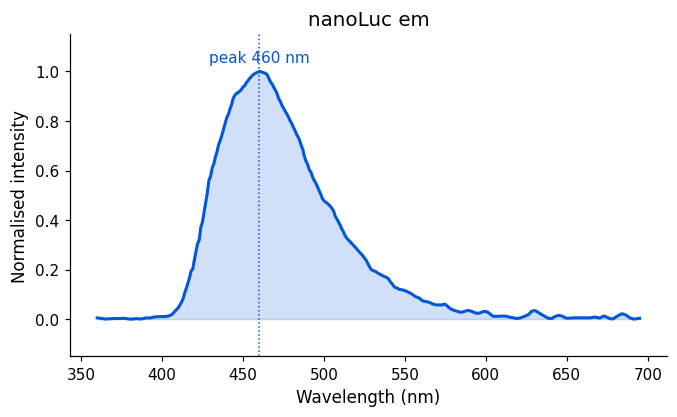

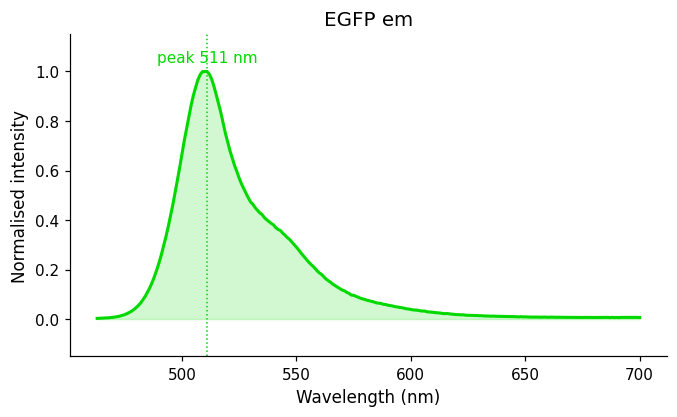

In [ ]:
from src.plotting import plot_spectrum

plot_spectrum("data/raw/nanoluc_em.csv")      # a CSV
plt.show()
plot_spectrum("data/raw/egfp_em.xlsx")        # an Excel file
plt.show()

Same function, two different file types, **same style**. Note the line colour: it's the real colour of light at each peak (460 nm blue, 507 nm green). Change the style once in `src/plotting.py`, and every figure changes.

Add a file to `data/raw/` tomorrow and nothing needs editing, just loop:

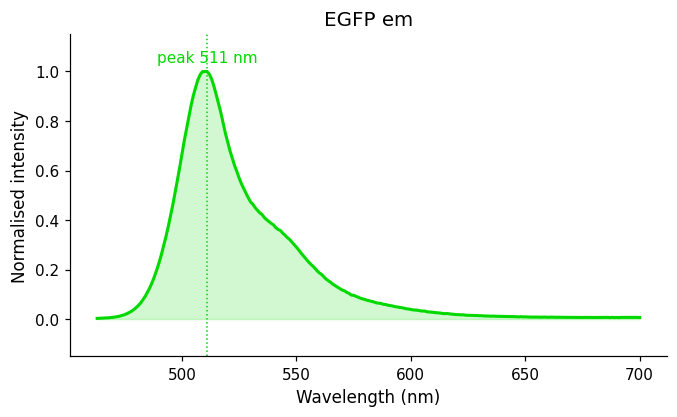

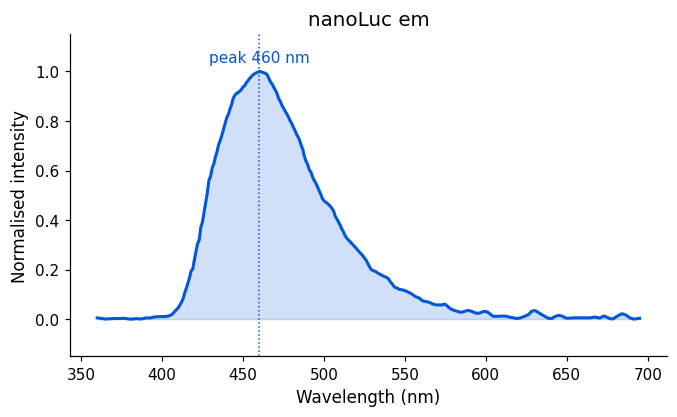

In [ ]:
for f in sorted(RAW.glob("*_em.*")):
    plot_spectrum(f, save_to=f"outputs/figures/{f.stem}.png")
    plt.show()

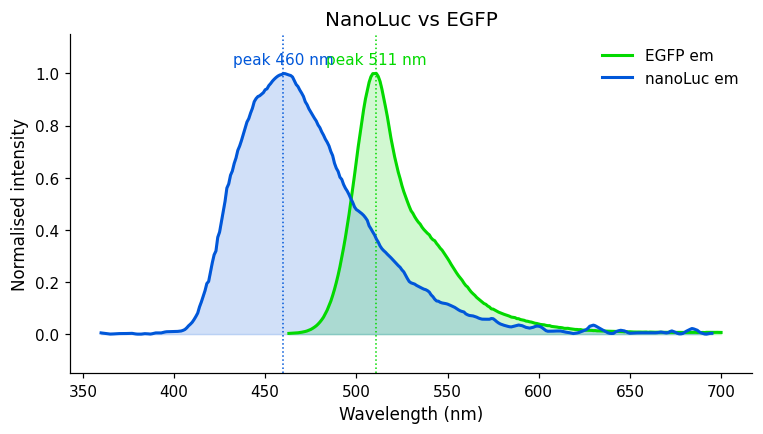

In [ ]:
# Overlay everything on ONE axis using ax=
fig, ax = plt.subplots(figsize=(8, 4))
for f in sorted(RAW.glob("*_em.*")):
    plot_spectrum(f, ax=ax)
ax.set_title("NanoLuc vs EGFP"); ax.legend(frameon=False)
fig.savefig("outputs/figures/overlay.png", dpi=300, bbox_inches="tight")
plt.show()

> Remember the rule: `outputs/` is disposable. Delete it, re-run the loop, everything comes back.

---
# 5️⃣ 🧑‍🤝‍🧑 Breakout rooms (5 min)

Pick whichever you like, in any order.

### Task 1: add a third spectrum, no code changes
We'll make a pretend third protein by shifting NanoLuc 40 nm redder. Save it into `data/raw/` as `mystery_em.csv`, then re-run the loop from section 4. Does it appear in the same style, with no changes to `plotting.py`?

*(Everything you need is in the hint below. This is about seeing the reuse work, not about finding data.)*

### Task 2: change the house style
Edit one thing in `src/plotting.py` (line width, fill transparency, annotation text). Reload it and re-plot.
Colab's file panel (📁) lets you open and edit the file. Then:
```python
import importlib, src.plotting; importlib.reload(src.plotting)
```

### Task 3 (stretch): add an `xlim` option
`plot_spectrum(path, xlim=(400, 600))` should zoom the x-axis. If `xlim` isn't given, nothing changes.

<details><summary>💡 Hints</summary>

- **Task 1:** copy this into a cell and run it, then re-run the loop:
  ```python
  df = pd.read_csv("data/raw/nanoluc_em.csv")
  df["wavelength"] += 40
  df = df.rename(columns={"nanoLuc em": "mystery em"})
  df.to_csv("data/raw/mystery_em.csv", index=False)
  ```
- **Task 2:** after editing, you **must** reload (or restart the runtime), otherwise Python keeps using the old version.
- **Task 3:** add `xlim=None` to the function's inputs, then `if xlim: ax.set_xlim(xlim)` before returning `ax`.
</details>

Solutions at the very bottom. Try first! 👇

In [ ]:
# ✏️ Breakouts

---
# 6️⃣ Take it back to your project (2 min)

`src/plotting.py` is a real file. Download it, drop it into the PyCharm project's `src/` folder (replace the old one), and re-run `python -m scripts.make_plots`. Same code, now part of your local project.

In [ ]:
try:
    from google.colab import files
    files.download("src/plotting.py")
except ImportError:
    print("Not in Colab: src/plotting.py is already on your machine.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 🧠 What we covered

| Idea | What to remember |
|---|---|
| **Package** | Someone else's toolkit. `pip install` it. |
| **Venv** | A labelled toolbox per project, so versions never clash. |
| **`requirements.txt`** | The packing list. Anyone can rebuild your environment. |
| **Structure** | `data/raw` (never edit) · `src` (reusable code) · `scripts` (things you run) · `outputs` (disposable) |
| **Reuse** | Write the plot once in `src/`. Import it. Call it on any file with the same layout. |
| **Editors** | Explore in a notebook, keep what works in files. |

## 🆘 If something goes wrong
1. **Read the error bottom to top.**
2. Check where you are: `os.getcwd()`, and `!ls`.
3. `ModuleNotFoundError: src` → you're in the wrong folder, or the `sys.path` cell hasn't been run.
4. After editing a `.py` file, **reload** it.
5. Copy the error line into Google or a chatbot.

**Data credit:** NanoLuc & EGFP spectra from [FPbase](https://www.fpbase.org) (CC BY-SA 4.0).

---
# 🔑 Breakout solutions

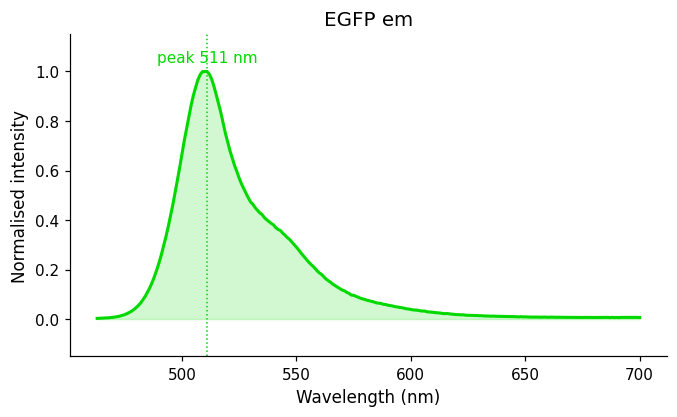

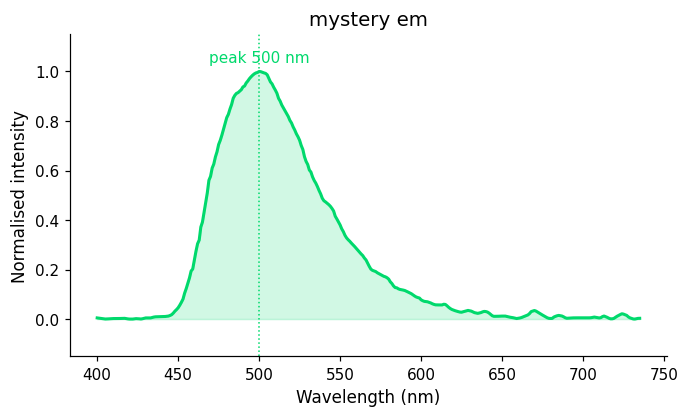

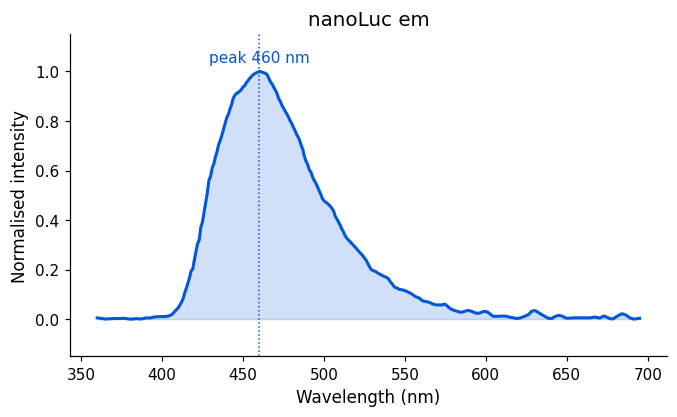

In [ ]:
# Task 1
df = pd.read_csv("data/raw/nanoluc_em.csv")
df["wavelength"] += 40
df.rename(columns={"nanoLuc em": "mystery em"}).to_csv("data/raw/mystery_em.csv", index=False)

for f in sorted(RAW.glob("*_em.*")):
    plot_spectrum(f); plt.show()

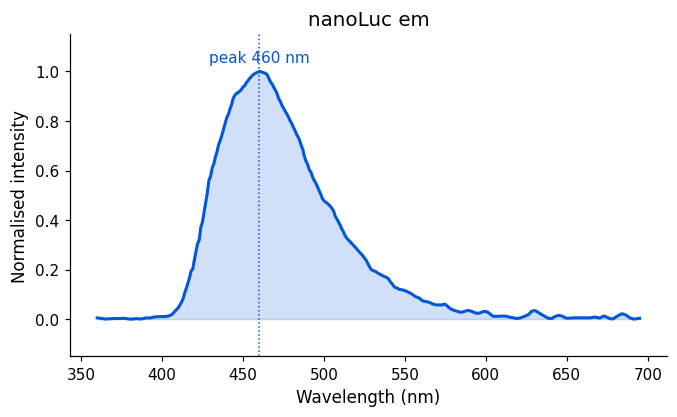

In [ ]:
# Task 2 (example): thicker line, stronger fill. Edit src/plotting.py, i.e. change
#   lw=2          -> lw=3
#   alpha=0.18    -> alpha=0.35
# then reload:
import importlib, src.plotting
importlib.reload(src.plotting)
from src.plotting import plot_spectrum
plot_spectrum("data/raw/nanoluc_em.csv"); plt.show()

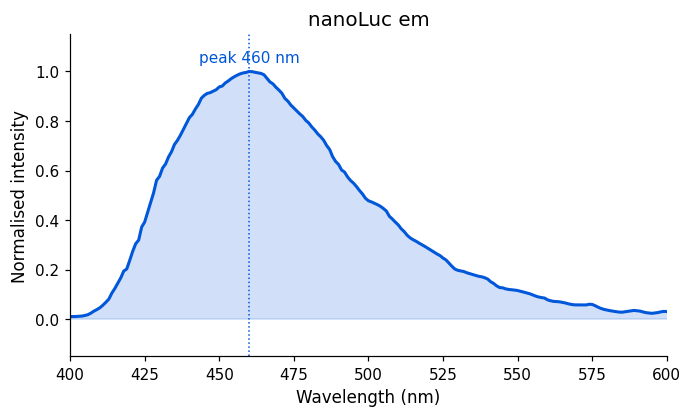

In [ ]:
# Task 3: the proper way is to edit src/plotting.py. The function becomes
#   def plot_spectrum(path, ax=None, normalise=True, color=None, save_to=None, xlim=None):
#       ...
#       if xlim:
#           ax.set_xlim(xlim)
#       return ax
# (then reload as in Task 2). A quick version you can run right now, without editing the file:
def plot_spectrum_zoom(path, xlim=None, **kwargs):
    ax = plot_spectrum(path, **kwargs)
    if xlim:
        ax.set_xlim(xlim)
    return ax

plot_spectrum_zoom("data/raw/nanoluc_em.csv", xlim=(400, 600)); plt.show()